# CARP para recolección de residuos: instancia grande (4×5 manzanas)

Este cuaderno es independiente del avance 2. Contiene:

1. Generación de una instancia tipo cuadrícula (30 nodos internos, `s` y `t`) donde **la mitad** de los arcos requieren servicio.
2. El modelo de Mourão y Almeida con las modificaciones acordadas:
   - `x` existe solo para los viajes que pueden servir (iniciales e intermedios); los viajes finales solo usan `y`.
   - Conectividad compacta (flujo de una mercancía): restricciones C1, C2 y C3. **C4 se omite** porque es suma de las C3.
   - Constante `M` ajustada por viaje y por nodo (no depende del número de nodos).
3. Resumen de la solución encadenando viajes por vehículo (inicial → intermedios → final).

In [2]:
%pip install gurobipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.9/14.9 MB 36.4 MB/s  0:00:00


In [3]:
import math, random
from collections import defaultdict

import gurobipy as gp
from gurobipy import GRB
import networkx as nx
import matplotlib.pyplot as plt

## 1. Instancia

Cuadrícula de 5 filas × 6 columnas de nodos (= 4×5 manzanas). El nodo de la fila $i$, columna $j$ se llama `i*6+j+1`, así que `"1"` está arriba a la izquierda y `"30"` abajo a la derecha.

- Filas 0, 2, 4: doble vía. Fila 1: hacia el este. Fila 3: hacia el oeste.
- Columnas 0, 2, 4: doble vía. Columnas 1 y 5: hacia el sur. Columna 3: hacia el norte.
- `s` (base de la cuadrilla) se conecta con los nodos 1 y 13; `t` (botadero) con los nodos 18 y 30.
- Los arcos requeridos son una muestra aleatoria (con semilla fija) de la mitad de los arcos de la cuadrícula.

In [4]:
NF, NC = 5, 6
random.seed(7)

def nid(i, j):
    return str(i*NC + j + 1)

U = [nid(i,j) for i in range(NF) for j in range(NC)]
V = ["s"] + U + ["t"]

# --- Calles ---
segmentos = {}
for i in range(NF):
    for j in range(NC-1):
        a, b = nid(i,j), nid(i,j+1)
        if i % 2 == 0:  segmentos[(a,b)] = "doble"
        elif i == 1:    segmentos[(a,b)] = "ida"
        else:           segmentos[(b,a)] = "ida"
for j in range(NC):
    for i in range(NF-1):
        a, b = nid(i,j), nid(i+1,j)
        if j % 2 == 0:       segmentos[(a,b)] = "doble"
        elif j in (1,5):     segmentos[(a,b)] = "ida"
        else:                segmentos[(b,a)] = "ida"

# --- Costos de deadheading (iguales en ambos sentidos de una calle doble) ---
d, arcos_grid = {}, []
for (a,b), tipo in segmentos.items():
    costo = random.randint(2,5)
    d[a,b] = costo
    arcos_grid.append((a,b))
    if tipo == "doble":
        d[b,a] = costo
        arcos_grid.append((b,a))

# --- Conexiones con s y t ---
A_extra = []
for u in [nid(0,0), nid(2,0)]:
    A_extra += [("s",u), (u,"s")]
for u in [nid(2,5), nid(4,5)]:
    A_extra += [("t",u), (u,"t")]
for (i,j) in A_extra:
    d[i,j] = 8 if "s" in (i,j) else 10

A = gp.tuplelist(arcos_grid + A_extra)

# --- Arcos requeridos, demandas y costos de servicio ---
AR = gp.tuplelist(random.sample(arcos_grid, len(arcos_grid)//2))
q = {a: random.choice([500,1000,1500,2000]) for a in AR}
c = {a: 2*d[a] for a in AR}          # servir cuesta más que pasar

# --- Verificación ---
G = nx.DiGraph(); G.add_edges_from(A)
assert nx.is_strongly_connected(G), "El grafo no es fuertemente conexo"

# --- Vehículos, capacidad, ell y L ---
P, W = 2, 15000
m  = len(AR)
QT = sum(q.values())

acum = ell = 0
for dem in sorted(q.values(), reverse=True):
    if acum + dem <= W:
        acum += dem; ell += 1
    else:
        break
L_cap = math.ceil(m/ell)
L = max(L_cap, 2*P)

R = list(range(1, L+1))
R_iniciales   = list(range(1, P+1))
R_finales     = list(range(P+1, 2*P+1))
R_intermedios = list(range(2*P+1, L+1))
R_servicio    = R_iniciales + R_intermedios

print("Nodos:", len(V), "| Arcos:", len(A), "| Requeridos:", m)
print("Demanda total:", QT, "| QT/W =", round(QT/W,2), "| cota inferior de viajes:", math.ceil(QT/W))
print("ell =", ell, "| L_cap =", L_cap, "| L =", L)
print("Iniciales:", R_iniciales, "| Finales:", R_finales, "| Intermedios:", R_intermedios)

Nodos: 32 | Arcos: 84 | Requeridos: 38
Demanda total: 50500 | QT/W = 3.37 | cota inferior de viajes: 4
ell = 7 | L_cap = 6 | L = 6
Iniciales: [1, 2] | Finales: [3, 4] | Intermedios: [5, 6]


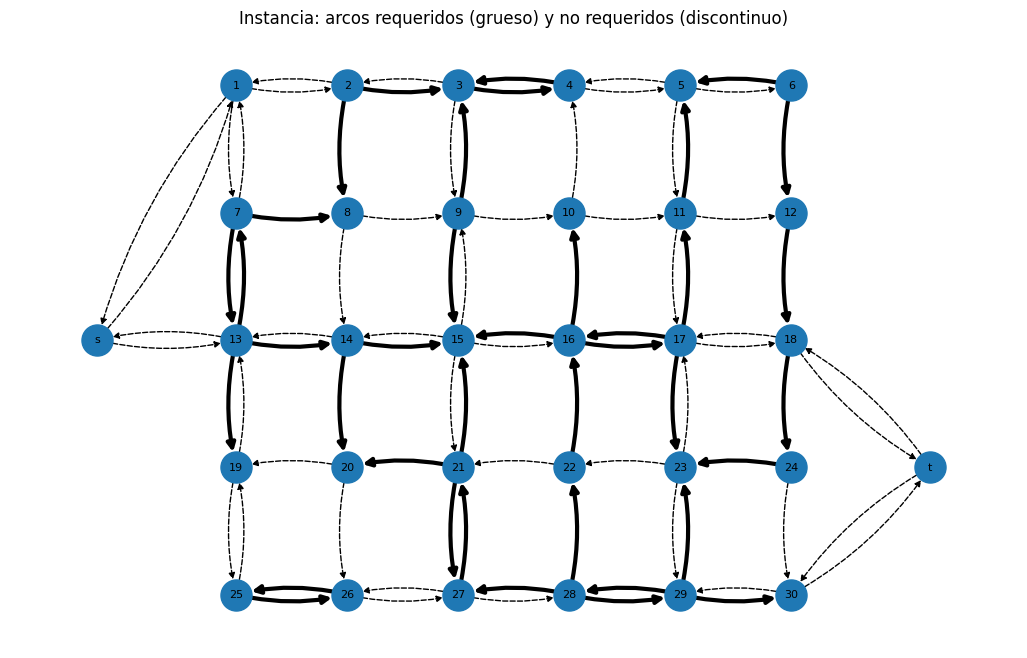

In [5]:
# --- Posiciones y gráfico de la instancia ---
pos = {nid(i,j): (2*j, 2*(NF-1-i)) for i in range(NF) for j in range(NC)}
pos["s"] = (-2.5, 4.0)
pos["t"] = (12.5, 2.0)

D = nx.DiGraph(); D.add_nodes_from(V); D.add_edges_from(A)
no_req = [a for a in A if a not in AR]

plt.figure(figsize=(13,8))
nx.draw_networkx_nodes(D, pos, node_size=500)
nx.draw_networkx_labels(D, pos, font_size=8)
nx.draw_networkx_edges(D, pos, edgelist=no_req, arrows=True, node_size=500,
                       arrowsize=9, width=1, style="dashed",
                       connectionstyle="arc3,rad=0.12")
nx.draw_networkx_edges(D, pos, edgelist=list(AR), arrows=True, node_size=500,
                       arrowsize=12, width=3, connectionstyle="arc3,rad=0.12")
plt.title("Instancia: arcos requeridos (grueso) y no requeridos (discontinuo)")
plt.axis("off")
plt.show()

## 2. Modelo

Variables:

- $x^r_{ij}\in\{0,1\}$: el arco requerido $(i,j)$ se sirve en el viaje $r$. **Solo existe para $r\in R_{\text{servicio}}$.**
- $y^r_{ij}\in\mathbb{Z}_{\ge 0}$: veces que se recorre $(i,j)$ sin servir en el viaje $r$.

`recorrido(r,i,j)` devuelve $x+y$ si el arco es requerido y el viaje puede servir, y solo $y$ en cualquier otro caso. Es una abreviatura de código, no introduce variables.

In [6]:
model = gp.Model("CARP_grande")

x = model.addVars([(r,i,j) for r in R_servicio for (i,j) in AR],
                  vtype=GRB.BINARY, name="x")
y = model.addVars([(r,i,j) for r in R for (i,j) in A],
                  vtype=GRB.INTEGER, lb=0, name="y")

def recorrido(r, i, j):
    if r in R_finales:
        return y[r,i,j]
    if (i,j) in AR:
        return x[r,i,j] + y[r,i,j]
    return y[r,i,j]

def uso_conexion(r, i, j):
    # La conexión {i,j} se usa si se recorre en cualquiera de sus sentidos
    expr = 0
    if (i,j) in A: expr += recorrido(r,i,j)
    if (j,i) in A: expr += recorrido(r,j,i)
    return expr

model.setObjective(
    gp.quicksum(c[i,j]*x[r,i,j] for r in R_servicio for (i,j) in AR)
    + gp.quicksum(d[i,j]*y[r,i,j] for r in R for (i,j) in A),
    GRB.MINIMIZE
)

Restricted license - for non-production use only - expires 2027-11-29


### Restricciones (2)–(11)

In [7]:
# (2) continuidad en nodos internos
model.addConstrs(
    (gp.quicksum(recorrido(r,i,j) for (i,j) in A if j == v)
     - gp.quicksum(recorrido(r,i,j) for (i,j) in A if i == v) == 0
     for v in U for r in R),
    name="R2")

# (3) viajes iniciales: balance en s
model.addConstrs(
    (gp.quicksum(recorrido(r,i,j) for (i,j) in A if i == "s")
     - gp.quicksum(recorrido(r,i,j) for (i,j) in A if j == "s") == 1
     for r in R_iniciales),
    name="R3")

# (4) viajes iniciales: llegan una vez a t
model.addConstrs(
    (gp.quicksum(y[r,i,j] for (i,j) in A if j == "t") == 1
     for r in R_iniciales),
    name="R4")

# (5) viajes iniciales: no salen de t
model.addConstrs(
    (gp.quicksum(y[r,i,j] for (i,j) in A if i == "t") == 0
     for r in R_iniciales),
    name="R5")

# (6) viajes finales: balance en s (solo y)
model.addConstrs(
    (-gp.quicksum(recorrido(r,i,j) for (i,j) in A if i == "s")
     + gp.quicksum(recorrido(r,i,j) for (i,j) in A if j == "s") == 1
     for r in R_finales),
    name="R6")

# (7) viajes finales: salen una vez de t
model.addConstrs(
    (gp.quicksum(y[r,i,j] for (i,j) in A if i == "t") == 1
     for r in R_finales),
    name="R7")

# (8) viajes finales: no entran a t
model.addConstrs(
    (gp.quicksum(y[r,i,j] for (i,j) in A if j == "t") == 0
     for r in R_finales),
    name="R8")

# (9) viajes intermedios: balance en s
model.addConstrs(
    (gp.quicksum(recorrido(r,i,j) for (i,j) in A if i == "s")
     - gp.quicksum(recorrido(r,i,j) for (i,j) in A if j == "s") == 0
     for r in R_intermedios),
    name="R9")

# (10) viajes intermedios: balance en t
model.addConstrs(
    (gp.quicksum(y[r,i,j] for (i,j) in A if i == "t")
     - gp.quicksum(y[r,i,j] for (i,j) in A if j == "t") == 0
     for r in R_intermedios),
    name="R10")

# (11) viajes intermedios: a lo sumo una salida de t
model.addConstrs(
    (gp.quicksum(y[r,i,j] for (i,j) in A if i == "t") <= 1
     for r in R_intermedios),
    name="R11")

{5: <gurobi.Constr *Awaiting Model Update*>,
 6: <gurobi.Constr *Awaiting Model Update*>}

### Conectividad compacta (flujo de una mercancía)

Para cada viaje $r$ y cada nodo $v\neq t$ se define $z^r_v=1$ si el nodo se usa. El nodo $t$ envía una unidad de flujo ficticio a cada nodo usado, y ese flujo solo puede circular por conexiones que el vehículo recorre (en cualquier sentido).

- **C1:** $z^r_v\le g^r_v\le M_{r,v}\,z^r_v$, con $g^r_v$ el número de arcos recorridos incidentes a $v$.
- **C2:** $f^r_{ij}\le (|V|-1)\cdot$ uso de la conexión $\{i,j\}$.
- **C3:** $\sum f_{\cdot v}-\sum f_{v\cdot}=z^r_v$ para $v\neq t$.
- **C4** (suministro de $t$) es la suma de las C3, por eso se omite.

La constante

$$M_{r,v}=2(k_r+1)+\min\{k_r,\ \deg_R(v)\},\qquad k_r=\begin{cases}\bar k & r\in R_{\text{servicio}}\\ 0 & r\in R_{\text{finales}}\end{cases}$$

donde $\bar k$ es el mayor número de arcos requeridos que caben en un viaje (demandas ordenadas de menor a mayor).

In [8]:
V_sin_t = [v for v in V if v != "t"]

# --- Cota M[r,v] ---
acum, k_bar = 0, 0
for dem in sorted(q.values()):
    if acum + dem <= W:
        acum += dem; k_bar += 1
    else:
        break
k_bar = min(k_bar, m)

deg_R = {v: sum(1 for (i,j) in AR if i == v or j == v) for v in V}

def M_rv(r, v):
    k = k_bar if r in R_servicio else 0
    return 2*(k + 1) + min(k, deg_R[v])

print("k_barra =", k_bar, "| M máximo =", max(M_rv(r,v) for r in R for v in V_sin_t))

# --- Conexiones no dirigidas y arcos del flujo auxiliar ---
E = sorted({tuple(sorted(a)) for a in A})
A_flujo = [(i,j) for (i,j) in E] + [(j,i) for (i,j) in E]
N_flujo = len(V_sin_t)
print("Conexiones:", len(E), "| Arcos de flujo auxiliar:", len(A_flujo))

# --- Variables auxiliares ---
z = model.addVars([(r,v) for r in R for v in V_sin_t], vtype=GRB.BINARY, name="z")
f = model.addVars([(r,i,j) for r in R for (i,j) in A_flujo],
                  vtype=GRB.CONTINUOUS, lb=0, name="f")

# --- C1: nodos utilizados ---
for r in R:
    for v in V_sin_t:
        uso_nodo = gp.quicksum(recorrido(r,i,j) for (i,j) in A if i == v or j == v)
        model.addConstr(z[r,v] <= uso_nodo,                name=f"C1a_{r}_{v}")
        model.addConstr(uso_nodo <= M_rv(r,v) * z[r,v],    name=f"C1b_{r}_{v}")

# --- C2: el flujo solo circula por conexiones usadas ---
for r in R:
    for (i,j) in A_flujo:
        model.addConstr(f[r,i,j] <= N_flujo * uso_conexion(r,i,j),
                        name=f"C2_{r}_{i}_{j}")

# --- C3: balance del flujo en nodos distintos de t ---
for r in R:
    for v in V_sin_t:
        entra = gp.quicksum(f[r,i,j] for (i,j) in A_flujo if j == v)
        sale  = gp.quicksum(f[r,i,j] for (i,j) in A_flujo if i == v)
        model.addConstr(entra - sale == z[r,v], name=f"C3_{r}_{v}")

# (C4 omitida: es la suma de las C3)

k_barra = 18 | M máximo = 43
Conexiones: 53 | Arcos de flujo auxiliar: 106


### Capacidad (13) y servicio exacto (14)

In [9]:
# (13) capacidad de cada viaje de servicio
model.addConstrs(
    (gp.quicksum(q[i,j]*x[r,i,j] for (i,j) in AR) <= W for r in R_servicio),
    name="R13")

# (14) cada arco requerido se sirve exactamente una vez
model.addConstrs(
    (gp.quicksum(x[r,i,j] for r in R_servicio) == 1 for (i,j) in AR),
    name="R14")

model.update()
print("Variables:", model.NumVars, "| Restricciones:", model.NumConstrs)
if model.NumVars > 2000 or model.NumConstrs > 2000:
    print("AVISO: se supera el límite de 2000 de la licencia de tamaño limitado de Gurobi.")

Variables: 1478 | Restricciones: 1434


In [10]:
model.Params.TimeLimit = 600     # segundos
model.Params.MIPGap = 0.0
model.optimize()

Set parameter TimeLimit to value 600
Set parameter MIPGap to value 0
Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (linux64 - "Ubuntu 24.04.5 LTS")

CPU model: Intel(R) Xeon(R) CPU @ 2.20GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 1 physical cores, 2 logical processors, using up to 2 threads

Non-default parameters:
TimeLimit  600
MIPGap  0

Optimize a model with 1434 rows, 1478 columns and 7950 nonzeros (Min)
Model fingerprint: 0xdada79c7
Model has 656 linear objective coefficients
Variable types: 636 continuous, 842 integer (338 binary)
Coefficient statistics:
  Matrix range     [1e+00, 2e+03]
  Objective range  [2e+00, 1e+01]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 2e+04]

Presolve removed 470 rows and 450 columns
Presolve time: 0.04s
Presolved: 964 rows, 1028 columns, 4622 nonzeros
Variable types: 424 continuous, 604 integer (284 binary)

Root relaxation: objective 4.432452e+02, 1111 iterations, 0.05 seconds (0.04 work units)

    Nodes    |    Curren

## 3. Solución

El modelo decide **viajes**, no rutas completas por vehículo. Para armar la ruta de cada vehículo se encadena: un viaje inicial, luego viajes intermedios, y un viaje final. La asignación de los viajes intermedios a los vehículos es un paso posterior al modelo (aquí se reparte de forma voraz para equilibrar costos).

In [11]:
def construir_ruta(arcos, inicio):
    # Recorrido euleriano (Hierholzer) de los arcos del viaje, desde 'inicio'
    adj = defaultdict(list)
    for (i,j) in arcos:
        adj[i].append(j)
    pila, ruta = [inicio], []
    while pila:
        v = pila[-1]
        if adj[v]:
            pila.append(adj[v].pop())
        else:
            ruta.append(pila.pop())
    return ruta[::-1]

def info_viaje(r):
    servidos = [(i,j) for (i,j) in AR if r in R_servicio and x[r,i,j].X > 0.5]
    dead = []
    for (i,j) in A:
        dead += [(i,j)] * int(round(y[r,i,j].X))
    carga = sum(q[a] for a in servidos)
    cs = sum(c[a] for a in servidos)
    cd = sum(d[a] for a in dead)
    inicio = "s" if r in R_iniciales else "t"
    ruta = construir_ruta(servidos + dead, inicio) if (servidos or dead) else []
    if ruta and len(ruta) != len(servidos) + len(dead) + 1:
        print(f"AVISO: la ruta del viaje {r} no usa todos los arcos")
    return dict(servidos=servidos, deadheading=dead, carga=carga,
                costo_servicio=cs, costo_deadheading=cd, costo=cs+cd,
                ruta=ruta, activo=bool(servidos or dead))

if model.SolCount > 0:
    info = {r: info_viaje(r) for r in R}

    print("Estado:", model.status, "| Objetivo:", round(model.ObjVal,2),
          "| Mejor cota:", round(model.ObjBound,2), "| Gap:", f"{100*model.MIPGap:.2f}%")

    print("\n" + "="*100)
    print("VIAJES")
    print("="*100)
    print(f"{'Viaje':<7}{'Tipo':<12}{'Basura':<9}{'C.Serv':<8}{'C.Dead':<8}{'C.Total':<9}Arcos servidos")
    for r in R:
        tipo = "Inicial" if r in R_iniciales else ("Final" if r in R_finales else "Intermedio")
        if not info[r]["activo"]:
            print(f"{r:<7}{tipo:<12}(no se usa)")
            continue
        i = info[r]
        print(f"{r:<7}{tipo:<12}{i['carga']:<9}{i['costo_servicio']:<8}"
              f"{i['costo_deadheading']:<8}{i['costo']:<9}{len(i['servidos'])} arcos")

    # ---- Encadenar viajes por vehículo ----
    intermedios = sorted([r for r in R_intermedios if info[r]["activo"]],
                         key=lambda r: -info[r]["costo"])
    vehiculos = {k: {"viajes": [k], "costo": info[k]["costo"] + info[P+k]["costo"]}
                 for k in range(1, P+1)}
    for r in intermedios:
        k = min(vehiculos, key=lambda k: vehiculos[k]["costo"])
        vehiculos[k]["viajes"].append(r)
        vehiculos[k]["costo"] += info[r]["costo"]
    for k in vehiculos:
        vehiculos[k]["viajes"].append(P+k)       # el final siempre cierra

    print("\n" + "="*100)
    print("RUTA POR VEHÍCULO (inicial -> intermedios -> final)")
    print("="*100)
    for k, v in vehiculos.items():
        ruta_total = []
        for r in v["viajes"]:
            ruta_total += info[r]["ruta"] if not ruta_total else info[r]["ruta"][1:]
        carga = sum(info[r]["carga"] for r in v["viajes"])
        print(f"\nVehículo {k}: viajes {v['viajes']} | basura {carga} | costo {v['costo']}")
        print("  " + " -> ".join(ruta_total))

    total = sum(info[r]["costo"] for r in R)
    print("\nBasura total recogida:", sum(info[r]["carga"] for r in R), "de", QT)
    print("Costo total calculado:", total, "| Objetivo del modelo:", round(model.ObjVal,2))
else:
    print("No hay solución. Estado de Gurobi:", model.status)

Estado: 2 | Objetivo: 487.0 | Mejor cota: 487.0 | Gap: 0.00%

VIAJES
Viaje  Tipo        Basura   C.Serv  C.Dead  C.Total  Arcos servidos
1      Inicial     13000    98      69      167      12 arcos
2      Inicial     12000    52      31      83       9 arcos
3      Final       0        0       35      35       0 arcos
4      Final       0        0       35      35       0 arcos
5      Intermedio  12000    48      34      82       8 arcos
6      Intermedio  13500    56      29      85       9 arcos

RUTA POR VEHÍCULO (inicial -> intermedios -> final)

Vehículo 1: viajes [1, 5, 3] | basura 25000 | costo 284
  s -> 1 -> 7 -> 8 -> 9 -> 3 -> 2 -> 3 -> 4 -> 3 -> 2 -> 8 -> 9 -> 15 -> 21 -> 20 -> 19 -> 13 -> 19 -> 13 -> 14 -> 15 -> 16 -> 15 -> 16 -> 17 -> 23 -> 29 -> 30 -> t -> 30 -> 29 -> 28 -> 27 -> 21 -> 15 -> 21 -> 27 -> 28 -> 22 -> 16 -> 10 -> 11 -> 12 -> 18 -> t -> 18 -> 17 -> 16 -> 15 -> 14 -> 13 -> s

Vehículo 2: viajes [2, 6, 4] | basura 25500 | costo 203
  s -> 13 -> 7 -> 13 -> 14 -

## 4. Gráficos de los viajes

En rojo grueso los arcos **servidos**, en negro los arcos recorridos **sin servicio**, y en gris discontinuo el resto de la red.

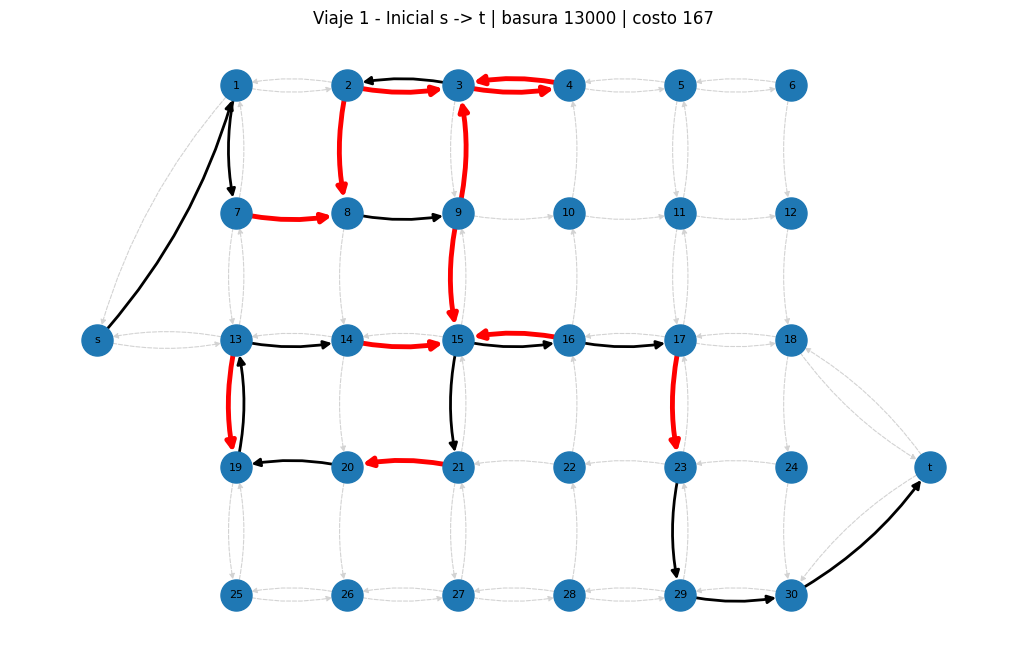

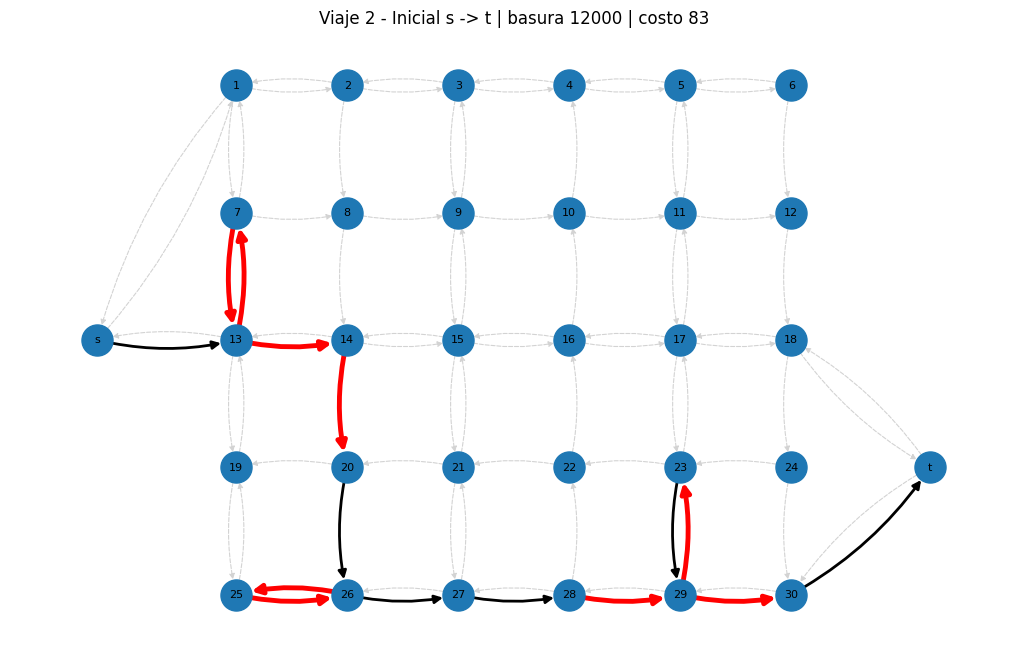

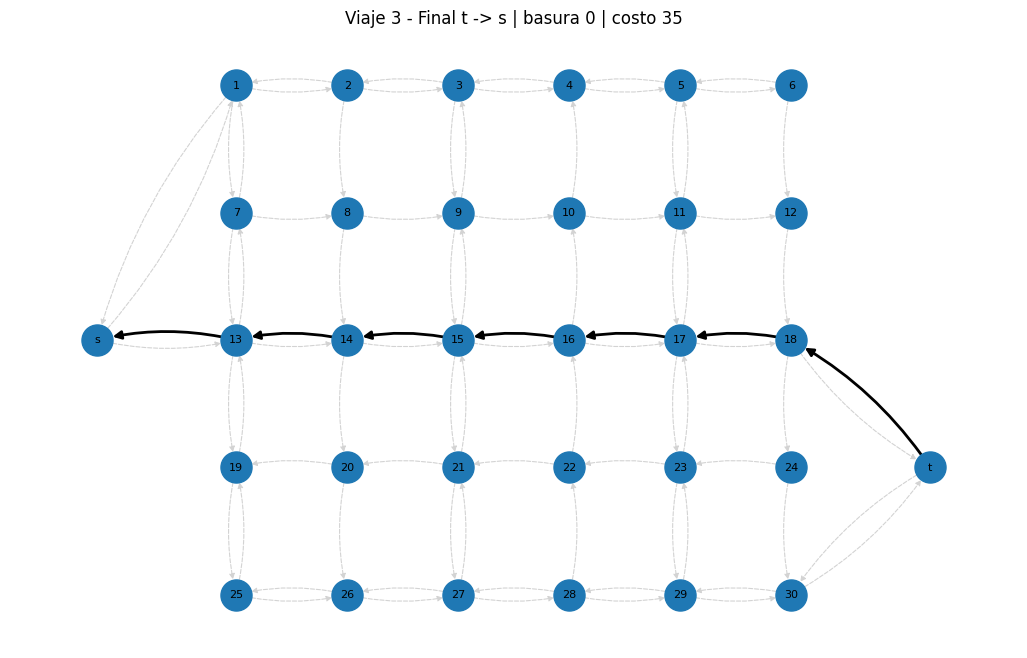

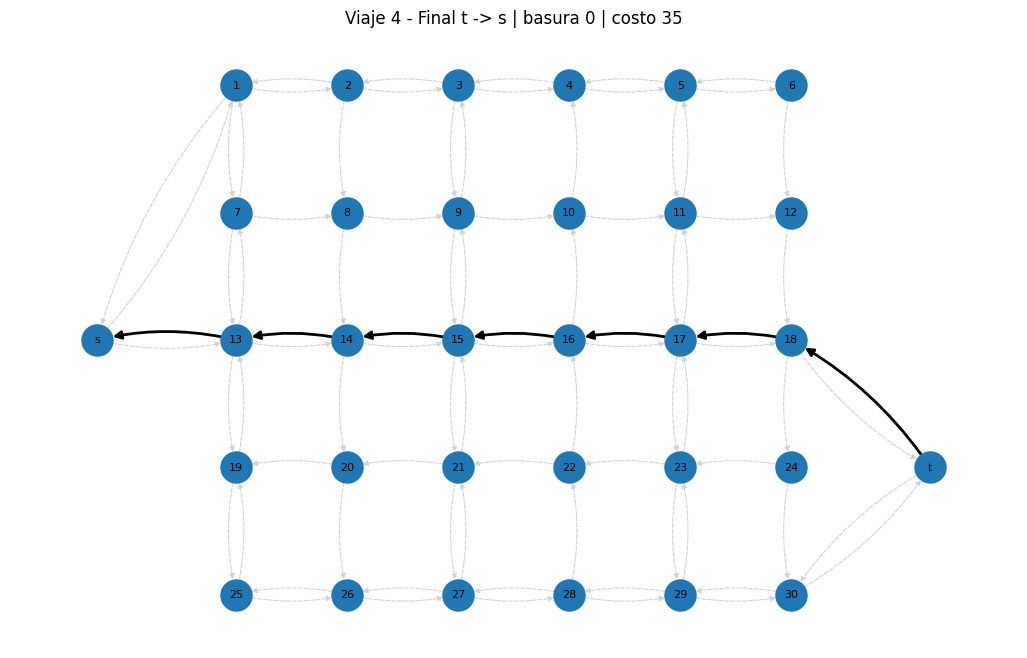

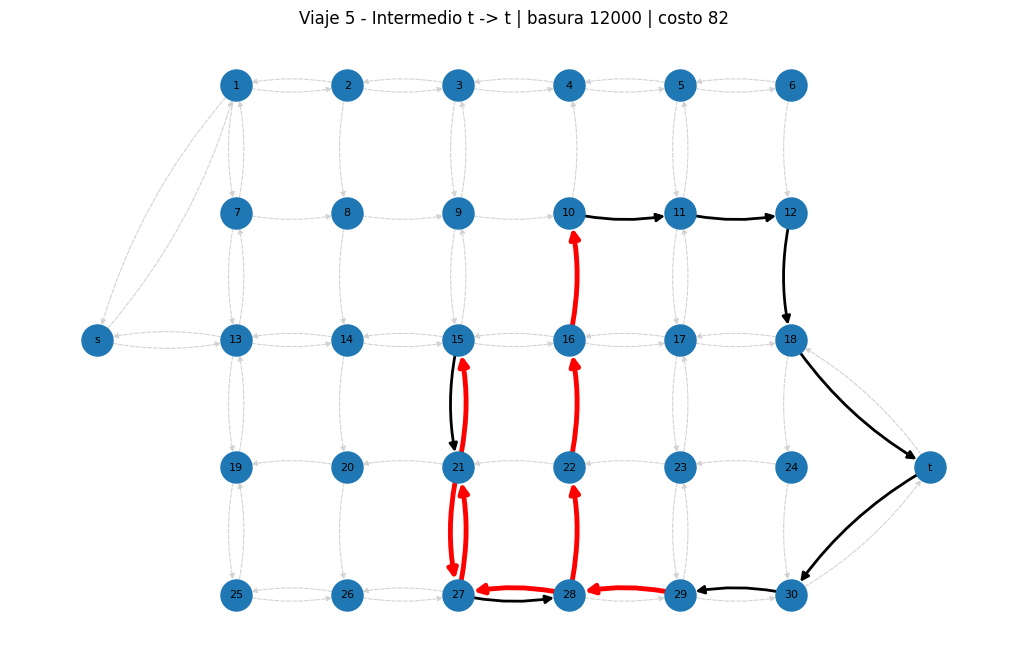

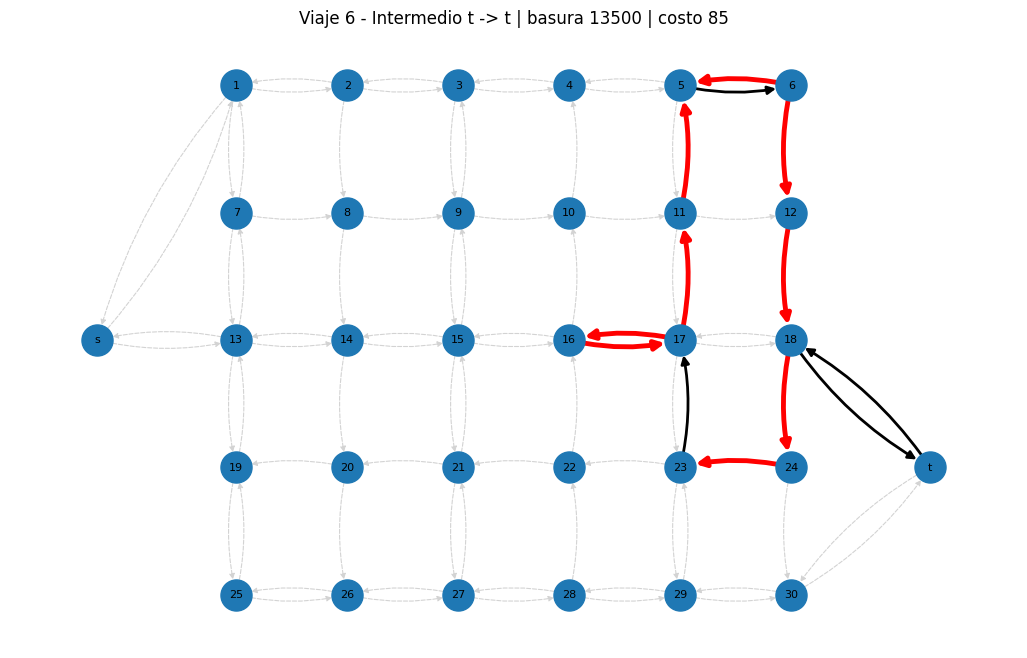

In [12]:
if model.SolCount > 0:
    for r in R:
        if not info[r]["activo"]:
            continue
        serv = list(set(info[r]["servidos"]))
        dead = [a for a in set(info[r]["deadheading"]) if a not in serv]
        resto = [a for a in A if a not in serv and a not in dead]
        tipo = "Inicial s -> t" if r in R_iniciales else ("Final t -> s" if r in R_finales else "Intermedio t -> t")

        plt.figure(figsize=(13,8))
        nx.draw_networkx_nodes(D, pos, node_size=500)
        nx.draw_networkx_labels(D, pos, font_size=8)
        nx.draw_networkx_edges(D, pos, edgelist=resto, arrows=True, node_size=500,
                               arrowsize=8, width=0.8, style="dashed", edge_color="lightgray",
                               connectionstyle="arc3,rad=0.12")
        nx.draw_networkx_edges(D, pos, edgelist=dead, arrows=True, node_size=500,
                               arrowsize=12, width=2, edge_color="black",
                               connectionstyle="arc3,rad=0.12")
        nx.draw_networkx_edges(D, pos, edgelist=serv, arrows=True, node_size=500,
                               arrowsize=14, width=3.5, edge_color="red",
                               connectionstyle="arc3,rad=0.12")
        plt.title(f"Viaje {r} - {tipo} | basura {info[r]['carga']} | costo {info[r]['costo']}")
        plt.axis("off")
        plt.show()